# Étape 1 — Analyse exploratoire des données du moteur IA

Deux jeux de données, deux propriétaires (database-per-service) :

| Jeu | Provenance | Lu depuis |
|---|---|---|
| **Points d'intérêt (POI)** | OpenStreetMap via Overpass (licence ODbL), `services/ai/scripts/collecter_pois.py` | base `voyara_ai` (conteneur `postgres-ai`, port 5435) |
| **Activités du catalogue de démo** | `services/catalog/scripts/seed_catalogue_demo.py` (86 activités) | constante `ACTIVITES` du script, **sans** lire la base `voyara_catalog` |
| **Météo** | Open-Meteo, `services/ai/scripts/rafraichir_meteo.py` | table `meteo_cache` de `voyara_ai` |

Questions : combien de POI par ville et par type ? Quelles valeurs manquent (horaires, arabe, prix) ?
Y a-t-il des doublons ? Les activités du catalogue ont-elles des POI autour d'elles (restaurant pour
le midi, plage, monument) ? Quels biais le moteur de recommandation héritera-t-il de ces données ?

Exécution : `.venv\Scripts\jupyter nbconvert --to notebook --execute --inplace notebooks\01_eda_donnees.ipynb`
(conteneur `postgres-ai` démarré, collecte effectuée). Les figures sont exportées dans `docs/ia/figures/`.

In [1]:
import importlib.util
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import dotenv_values
from sqlalchemy import create_engine

# Racine du dépôt, que le notebook soit lancé depuis notebooks/ ou depuis la racine
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docker-compose.yml").exists())
FIGURES = RACINE / "docs" / "ia" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(RACINE / "services" / "ai"))
from app.villes import VILLES, normaliser  # référentiel partagé avec la collecte

# Connexion à voyara_ai avec les paramètres de services/ai/.env (rien n'est affiché)
env = dotenv_values(RACINE / "services" / "ai" / ".env")
engine = create_engine(
    f"postgresql+psycopg2://{env['POSTGRES_USER']}:{env['POSTGRES_PASSWORD']}"
    f"@{env.get('POSTGRES_HOST', 'localhost')}:{env.get('POSTGRES_PORT', '5435')}/{env.get('POSTGRES_DB', 'voyara_ai')}"
)

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COULEURS = {"restaurant": "#d1495b", "cafe": "#edae49", "plage": "#00798c", "musee": "#6a4c93",
            "monument": "#8d6a3f", "souk": "#e07a5f", "parc": "#3d9970"}
ORDRE_VILLES = [v.nom for v in VILLES]


def sauver(fig, nom):
    fig.savefig(FIGURES / nom, bbox_inches="tight")
    print("figure ->", (FIGURES / nom).relative_to(RACINE).as_posix())


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))

## 1. Chargement

In [2]:
pois = pd.read_sql(
    "select id, type, nom, nom_en, nom_ar, ville, latitude, longitude, horaires_ouverture, "
    "horaires_normalises is not null as horaires_analysables, prix_moyen, source_id, maj_le from pois",
    engine,
)
meteo = pd.read_sql("select ville, date, temp_min, temp_max, precipitations, code_meteo, maj_le from meteo_cache", engine)

# Activités : constante du script de seed, chargée sans base ni service catalog
spec = importlib.util.spec_from_file_location(
    "seed_catalogue_demo", RACINE / "services" / "catalog" / "scripts" / "seed_catalogue_demo.py")
seed = importlib.util.module_from_spec(spec)
spec.loader.exec_module(seed)
activites = pd.DataFrame([{
    "titre": a["fr"][0], "ville": a["ville"], "zone": seed.ZONES[a["ville"]], "categorie": a["categorie"],
    "prix": a["prix"], "duree_min": a["duree"], "latitude": a["latitude"], "longitude": a["longitude"],
} for a in seed.ACTIVITES])

print(f"POI : {len(pois)} lignes, {pois.ville.nunique()} villes, {pois.type.nunique()} types")
print(f"Activités du seed : {len(activites)} sur {activites.zone.nunique()} zones")
print(f"Météo : {len(meteo)} jours en cache pour {meteo.ville.nunique()} villes")
pois.head()

POI : 1030 lignes, 8 villes, 7 types
Activités du seed : 86 sur 5 zones
Météo : 56 jours en cache pour 8 villes


,id,type,nom,nom_en,nom_ar,ville,latitude,longitude,horaires_ouverture,horaires_analysables,prix_moyen,source_id,maj_le
0,206,restaurant,Safsaf,Safsaf,الصفصاف,Sidi Bou Saïd,36.883477,10.331888,NaN,False,NaN,node/2313631873,2026-10-13 15:09:06.524985+00:00
1,208,restaurant,Joe's Pizza,NaN,جوز بيتزا,Sidi Bou Saïd,36.873845,10.320444,NaN,False,NaN,node/2439776739,2026-10-13 15:09:06.524985+00:00
2,9,musee,Lalla Hadria,NaN,NaN,Djerba,33.819909,11.044920,NaN,False,NaN,node/352842148,2026-10-13 15:06:04.209517+00:00
3,10,restaurant,La Rose Snack Bar,NaN,NaN,Djerba,33.874242,10.956377,NaN,False,NaN,node/1272100812,2026-10-13 15:06:04.209517+00:00
4,209,restaurant,Pizzeria Sugo,NaN,NaN,Sidi Bou Saïd,36.875838,10.328961,NaN,False,NaN,node/2520240709,2026-10-13 15:09:06.524985+00:00


## 2. Critère de « fini » de l'étape 1

Guide : **≥ 300 POI répartis sur au moins 5 villes, météo disponible pour Djerba, notebook exécuté sans erreur.**

In [3]:
assert len(pois) >= 300, f"seulement {len(pois)} POI"
assert pois.ville.nunique() >= 5, f"seulement {pois.ville.nunique()} villes"
assert (meteo.ville == "Djerba").any(), "pas de météo pour Djerba"
assert pois.source_id.is_unique, "source_id dupliqué"
print(f"OK : {len(pois)} POI, {pois.ville.nunique()} villes, {int((meteo.ville == 'Djerba').sum())} jours de météo à Djerba")

OK : 1030 POI, 8 villes, 7 jours de météo à Djerba


## 3. Volumes de POI par ville et par type

In [4]:
volumes = pd.crosstab(pois.ville, pois.type).reindex(ORDRE_VILLES).fillna(0).astype(int)
volumes = volumes[[t for t in COULEURS if t in volumes.columns]]
volumes["total"] = volumes.sum(axis=1)
print(volumes.to_string())
print()
print("Part de chaque type (toutes villes) :")
print((pois.type.value_counts(normalize=True) * 100).round(1).astype(str).add(" %").to_string())

type           restaurant  cafe  plage  musee  monument  souk  parc  total
ville                                                                     
Djerba                 51    60     10      7        51     0     8    187
Tunis                  60    60      0     12        60    25    19    236
Sidi Bou Saïd          55    42      3      4        24     2     4    134
Sousse                 60    60     12      5        10     6     8    161
Hammamet               60    60      4      0         2     3     8    137
Monastir               22    49      1      4        10     4     7     97
Tozeur                  9    19      0      4         0     2     9     43
Kairouan                5    17      0      3         6     3     1     35

Part de chaque type (toutes villes) :
type
cafe          35.6 %
restaurant    31.3 %
monument      15.8 %
parc           6.2 %
souk           4.4 %
musee          3.8 %
plage          2.9 %


figure ->

 docs/ia/figures/etape01_poi_par_ville_type.png


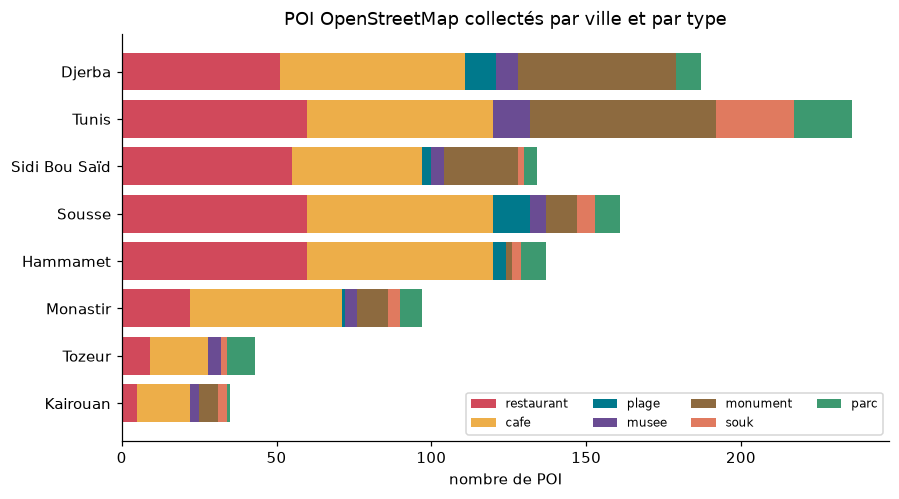

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
gauche = np.zeros(len(volumes))
for t in [c for c in volumes.columns if c != "total"]:
    ax.barh(volumes.index, volumes[t], left=gauche, color=COULEURS[t], label=t)
    gauche += volumes[t].to_numpy()
ax.invert_yaxis()
ax.set_xlabel("nombre de POI")
ax.set_title("POI OpenStreetMap collectés par ville et par type")
ax.legend(ncol=4, fontsize=8, loc="lower right")
sauver(fig, "etape01_poi_par_ville_type.png")
plt.show()

Le plafond de collecte (`--max-par-type`, 60 par défaut) se voit : les grandes villes saturent sur
`restaurant` et `cafe`. Sans lui, Tunis écraserait les autres villes dans tout classement
« par popularité de la zone ».

## 4. Valeurs manquantes

In [6]:
manquants = pd.DataFrame({
    "horaires (brut OSM)": pois.horaires_ouverture.isna(),
    "horaires analysables": ~pois.horaires_analysables,
    "nom_en": pois.nom_en.isna(),
    "nom_ar": pois.nom_ar.isna(),
    "prix_moyen": pois.prix_moyen.isna(),
})
taux_global = (manquants.mean() * 100).round(1)
print("Taux de valeurs manquantes, toutes villes (%) :")
print(taux_global.to_string())
taux_ville = (manquants.groupby(pois.ville).mean() * 100).reindex(ORDRE_VILLES).round(0)
print()
print(taux_ville.to_string())

# Parmi les horaires présents, combien le normaliseur sait-il lire ?
presents = pois.horaires_ouverture.notna()
print(f"\nHoraires présents : {presents.sum()} ; analysés : {(presents & pois.horaires_analysables).sum()} "
      f"({(presents & pois.horaires_analysables).sum() / max(presents.sum(), 1) * 100:.0f} %)")

Taux de valeurs manquantes, toutes villes (%) :
horaires (brut OSM)     93.2
horaires analysables    93.8
nom_en                  85.4
nom_ar                  71.3
prix_moyen              99.7

               horaires (brut OSM)  horaires analysables  nom_en  nom_ar  prix_moyen
ville                                                                               
Djerba                        96.0                  96.0    80.0    61.0       100.0
Tunis                         94.0                  95.0    86.0    57.0       100.0
Sidi Bou Saïd                 95.0                  95.0    77.0    67.0        99.0
Sousse                        86.0                  86.0    86.0    83.0        99.0
Hammamet                      96.0                  97.0    95.0    91.0       100.0
Monastir                      95.0                  96.0    92.0    73.0       100.0
Tozeur                        81.0                  84.0    88.0    88.0       100.0
Kairouan                     100.0       

figure -> docs/ia/figures/etape01_valeurs_manquantes.png


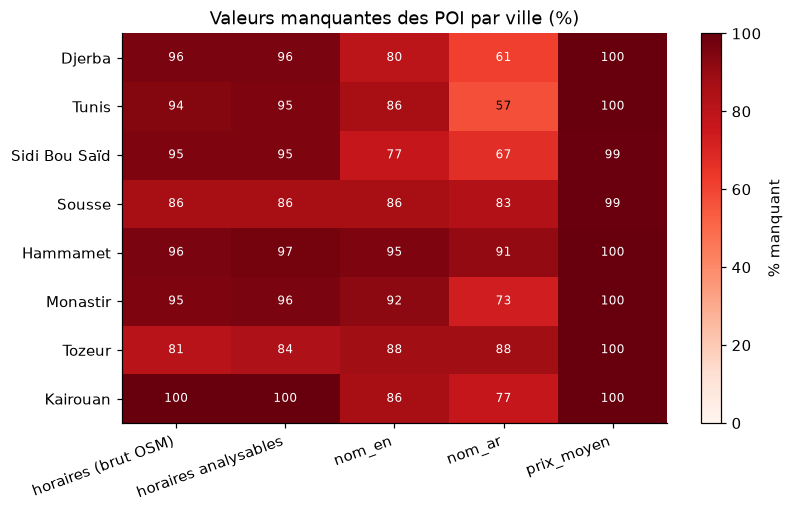

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.6))
im = ax.imshow(taux_ville.to_numpy(), cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(taux_ville.columns)), taux_ville.columns, rotation=20, ha="right")
ax.set_yticks(range(len(taux_ville.index)), taux_ville.index)
for i in range(taux_ville.shape[0]):
    for j in range(taux_ville.shape[1]):
        v = taux_ville.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "black")
fig.colorbar(im, ax=ax, label="% manquant")
ax.set_title("Valeurs manquantes des POI par ville (%)")
sauver(fig, "etape01_valeurs_manquantes.png")
plt.show()

Exemples d'horaires OSM que le normaliseur ne sait pas lire (le texte brut reste disponible pour le
LLM, mais le solveur d'itinéraire ne pourra pas s'en servir comme contrainte) :

In [8]:
non_lus = pois[pois.horaires_ouverture.notna() & ~pois.horaires_analysables]
print(non_lus.horaires_ouverture.value_counts().head(10).to_string())

horaires_ouverture
Mo-Su                                       1
sunrise-sunset                              1
Mo                                          1
Tu-Su 09:00-17:00 (Ramadhan 10:00-16:00)    1
Mo-Sa 12:00 - 23:00                         1
Mo-Sa                                       1


## 5. Carte des points

figure -> docs/ia/figures/etape01_carte_poi_activites.png


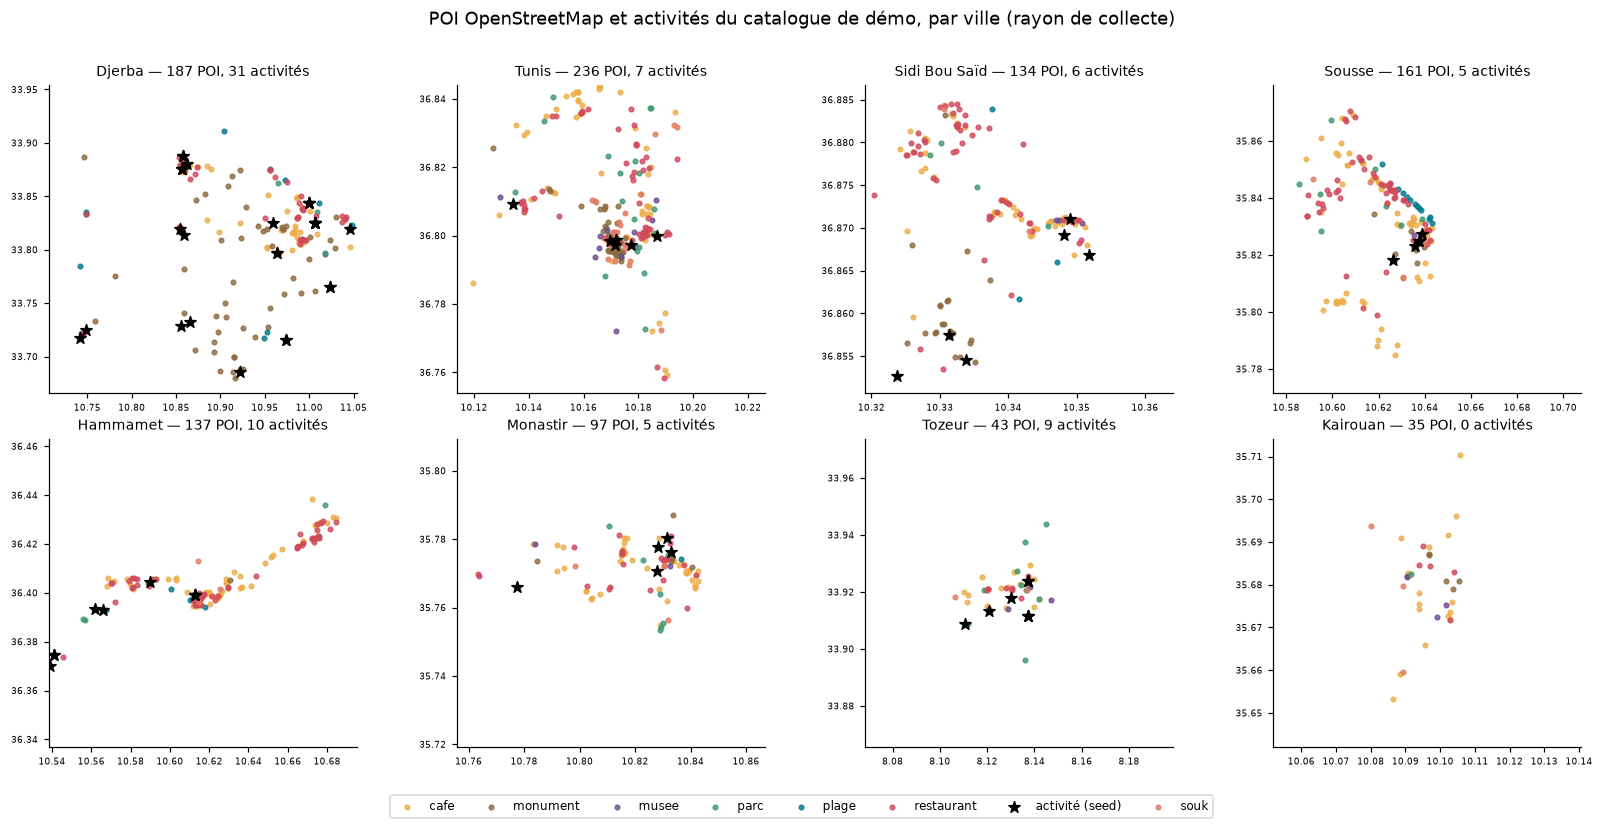

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for ax, ville in zip(axes.flat, VILLES):
    rayon_lat = ville.rayon_m / 111_000
    rayon_lon = rayon_lat / np.cos(np.radians(ville.latitude))
    sous = pois[pois.ville == ville.nom]
    for t, groupe in sous.groupby("type"):
        ax.scatter(groupe.longitude, groupe.latitude, s=9, color=COULEURS[t], label=t, alpha=0.8)
    proches = activites[(abs(activites.latitude - ville.latitude) < rayon_lat)
                        & (abs(activites.longitude - ville.longitude) < rayon_lon)]
    ax.scatter(proches.longitude, proches.latitude, s=60, marker="*", color="black", label="activité (seed)")
    ax.set_xlim(ville.longitude - rayon_lon, ville.longitude + rayon_lon)
    ax.set_ylim(ville.latitude - rayon_lat, ville.latitude + rayon_lat)
    ax.set_aspect(1 / np.cos(np.radians(ville.latitude)))
    ax.set_title(f"{ville.nom} — {len(sous)} POI, {len(proches)} activités", fontsize=9)
    ax.tick_params(labelsize=6)
poignees = {l: h for ax in axes.flat for h, l in zip(*ax.get_legend_handles_labels())}
fig.legend(poignees.values(), poignees.keys(), loc="lower center", ncol=8, fontsize=8)
fig.suptitle("POI OpenStreetMap et activités du catalogue de démo, par ville (rayon de collecte)")
fig.tight_layout(rect=(0, 0.05, 1, 0.97))
sauver(fig, "etape01_carte_poi_activites.png")
plt.show()

figure -> docs/ia/figures/etape01_carte_tunisie.png


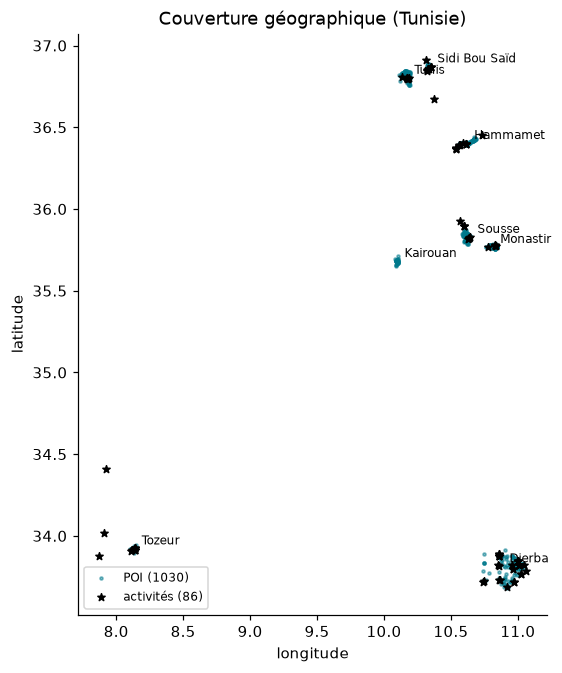

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 7))
ax.scatter(pois.longitude, pois.latitude, s=4, color="#00798c", alpha=0.5, label=f"POI ({len(pois)})")
ax.scatter(activites.longitude, activites.latitude, s=25, marker="*", color="black", label=f"activités ({len(activites)})")
for v in VILLES:
    ax.annotate(v.nom, (v.longitude, v.latitude), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set_aspect(1 / np.cos(np.radians(35)))
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Couverture géographique (Tunisie)")
ax.legend(fontsize=8, loc="lower left")
sauver(fig, "etape01_carte_tunisie.png")
plt.show()

## 6. Doublons

`source_id` est unique par construction (upsert). On cherche les doublons **sémantiques** : le même
lieu cartographié deux fois dans OSM (un nœud et un contour, par exemple), c'est-à-dire le même nom
normalisé dans la même ville, à moins de 50 m.

In [11]:
pois["nom_normalise"] = pois.nom.map(normaliser)
paires = []
for (ville, nom), groupe in pois.groupby(["ville", "nom_normalise"]):
    if len(groupe) < 2:
        continue
    lignes = groupe.to_dict("records")
    for i in range(len(lignes)):
        for j in range(i + 1, len(lignes)):
            d = haversine_km(lignes[i]["latitude"], lignes[i]["longitude"], lignes[j]["latitude"], lignes[j]["longitude"]) * 1000
            paires.append({"ville": ville, "nom": lignes[i]["nom"], "a": lignes[i]["source_id"],
                           "b": lignes[j]["source_id"], "distance_m": round(d)})
paires = pd.DataFrame(paires, columns=["ville", "nom", "a", "b", "distance_m"])
doublons = paires[paires.distance_m < 50]
print(f"Noms répétés dans une même ville : {len(paires)} paires ; dont à moins de 50 m : {len(doublons)}")
print(f"Taux de doublons probables : {len(doublons) / len(pois) * 100:.1f} % des POI")
print(paires.sort_values("distance_m").head(12).to_string(index=False))

Noms répétés dans une même ville : 250 paires ; dont à moins de 50 m : 21
Taux de doublons probables : 2.0 % des POI
        ville                           nom                a                b  distance_m
     Monastir               Café El Majless  node/5100914264  node/5208020106           0
        Tunis                  Story coffee  node/5422622828  node/5422635922           1
       Sousse                  مشاوي الحطاب node/11388194869 node/11388194871           4
       Djerba    Henchir Bourgou - mausolée    way/436514753   way/1315226033           5
     Monastir                        Haroun  node/2475485379    way/209995815           7
       Djerba    Gaïa Stylish Coffee & Food  node/3737502881    way/370023816           7
Sidi Bou Saïd Basilique de Damous el Karita    way/131384746    way/659013865          13
       Djerba                  Henchir Tala    way/253063358    way/319527428          17
     Monastir   mausolée de Habib Bourguiba   node/320658783     way/4473

## 7. Activités du catalogue de démo (seed)

In [12]:
print(pd.crosstab(activites.zone, activites.categorie, margins=True, margins_name="total").to_string())
print()
print(activites[["prix", "duree_min"]].describe().round(1).to_string())

categorie              Aventure  Culture  Désert  Gastronomie  Mer  total
zone                                                                     
Djerba                        6       11       2            5    8     32
Hammamet                      2        5       0            2    3     12
Sousse / Monastir             2        6       0            2    4     14
Tozeur                        2        3       5            2    0     12
Tunis / Sidi Bou Saïd         2        9       0            3    2     16
total                        14       34       7           14   17     86

        prix  duree_min
count   86.0       86.0
mean    60.2      195.8
std     46.3      315.0
min     15.0       20.0
25%     35.0       90.0
50%     45.0      150.0
75%     70.0      180.0
max    320.0     2880.0


figure -> docs/ia/figures/etape01_activites_seed.png


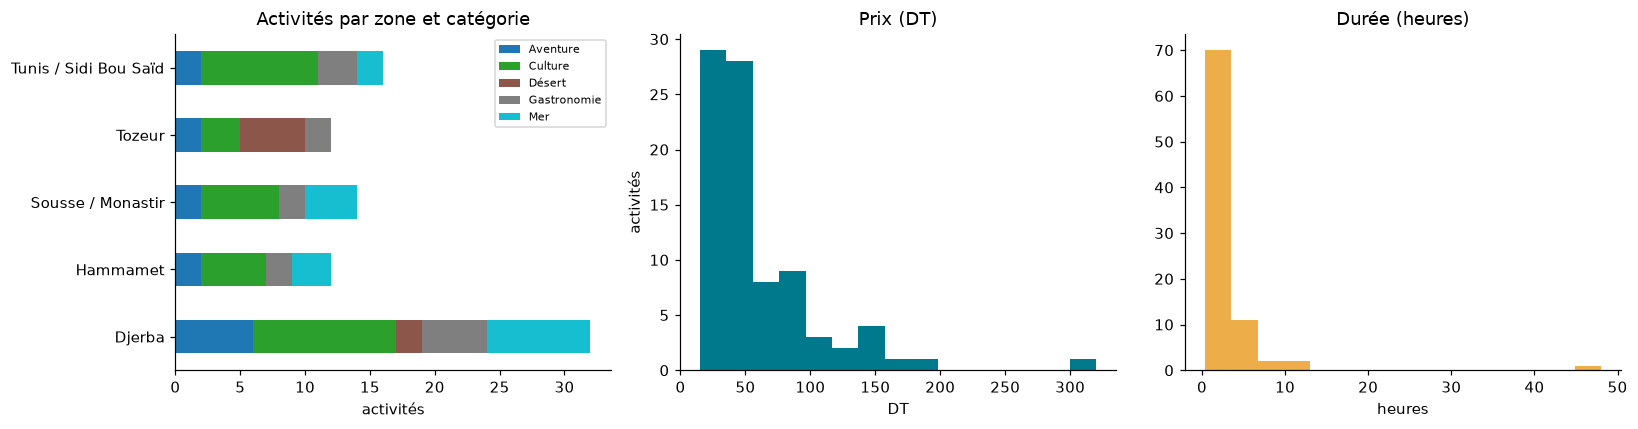

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pd.crosstab(activites.zone, activites.categorie).plot.barh(stacked=True, ax=axes[0], colormap="tab10")
axes[0].set_title("Activités par zone et catégorie"); axes[0].set_xlabel("activités"); axes[0].set_ylabel("")
axes[0].legend(fontsize=7)
axes[1].hist(activites.prix, bins=15, color="#00798c")
axes[1].set_title("Prix (DT)"); axes[1].set_xlabel("DT"); axes[1].set_ylabel("activités")
axes[2].hist(activites.duree_min / 60, bins=15, color="#edae49")
axes[2].set_title("Durée (heures)"); axes[2].set_xlabel("heures")
fig.tight_layout()
sauver(fig, "etape01_activites_seed.png")
plt.show()

## 8. Couverture croisée activités ↔ POI

Pour construire une journée (activité le matin, restaurant le midi, plage ou monument l'après-midi),
chaque activité a besoin de POI à proximité. On mesure la distance de chaque activité à son POI le
plus proche, tous types confondus et pour les restaurants.

In [14]:
d = haversine_km(activites.latitude.to_numpy()[:, None], activites.longitude.to_numpy()[:, None],
                 pois.latitude.to_numpy()[None, :], pois.longitude.to_numpy()[None, :])
activites["poi_plus_proche_km"] = d.min(axis=1)
est_resto = (pois.type == "restaurant").to_numpy()
activites["restaurant_plus_proche_km"] = d[:, est_resto].min(axis=1)
activites["poi_a_1km"] = (d < 1).sum(axis=1)

resume = activites.groupby("zone").agg(
    activites=("titre", "size"),
    poi_plus_proche_km_mediane=("poi_plus_proche_km", "median"),
    restaurant_km_mediane=("restaurant_plus_proche_km", "median"),
    poi_a_1km_moyenne=("poi_a_1km", "mean"),
    isolees_plus_2km=("poi_plus_proche_km", lambda s: int((s > 2).sum())),
).round(2)
print(resume.to_string())
isolees = activites[activites.poi_plus_proche_km > 2].sort_values("poi_plus_proche_km", ascending=False)
print(f"\nActivités sans POI à moins de 2 km : {len(isolees)} / {len(activites)}")
print(isolees[["titre", "zone", "poi_plus_proche_km"]].round(1).head(15).to_string(index=False))

                       activites  poi_plus_proche_km_mediane  restaurant_km_mediane  poi_a_1km_moyenne  isolees_plus_2km
zone                                                                                                                    
Djerba                        32                        0.82                   0.83               6.84                 3
Hammamet                      12                        0.20                   0.43              19.42                 1
Sousse / Monastir             14                        0.09                   0.36              23.71                 4
Tozeur                        12                        0.35                   0.76               9.50                 3
Tunis / Sidi Bou Saïd         16                        0.04                   0.23              47.31                 2

Activités sans POI à moins de 2 km : 13 / 86
                                                 titre                  zone  poi_plus_proche_km
          

In [15]:
# Villes collectées sans activité dans leur rayon de collecte (POI inutilisables pour un itinéraire réservable)
for v in VILLES:
    dist = haversine_km(v.latitude, v.longitude, activites.latitude, activites.longitude)
    n = int((dist <= v.rayon_m / 1000).sum())
    print(f"{v.nom:<15} activités dans le rayon : {n:>3}   POI : {int((pois.ville == v.nom).sum()):>4}")

Djerba          activités dans le rayon :  30   POI :  187
Tunis           activités dans le rayon :   7   POI :  236
Sidi Bou Saïd   activités dans le rayon :   5   POI :  134
Sousse          activités dans le rayon :   5   POI :  161
Hammamet        activités dans le rayon :   7   POI :  137
Monastir        activités dans le rayon :   5   POI :   97
Tozeur          activités dans le rayon :   9   POI :   43
Kairouan        activités dans le rayon :   0   POI :   35


figure -> docs/ia/figures/etape01_distance_activite_poi.png


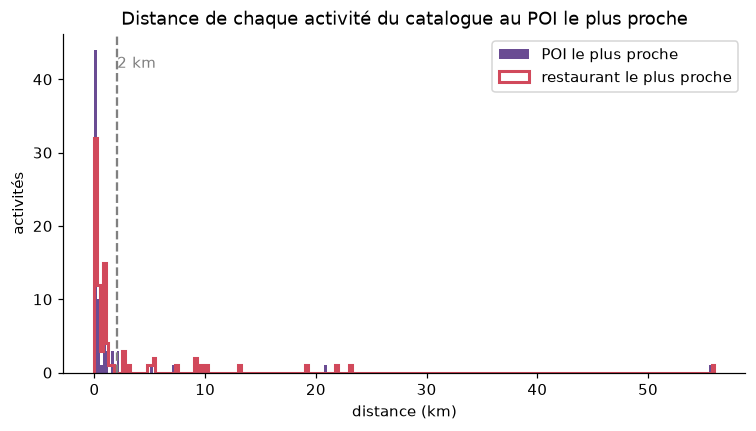

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
bornes = np.arange(0, max(6.5, activites.poi_plus_proche_km.max() + 0.5), 0.25)
ax.hist(activites.poi_plus_proche_km.clip(upper=bornes[-1]), bins=bornes, color="#6a4c93", label="POI le plus proche")
ax.hist(activites.restaurant_plus_proche_km.clip(upper=bornes[-1]), bins=bornes, histtype="step", lw=2,
        color="#d1495b", label="restaurant le plus proche")
ax.axvline(2, ls="--", color="grey"); ax.text(2.05, ax.get_ylim()[1] * 0.9, "2 km", color="grey")
ax.set_xlabel("distance (km)"); ax.set_ylabel("activités")
ax.set_title("Distance de chaque activité du catalogue au POI le plus proche")
ax.legend()
sauver(fig, "etape01_distance_activite_poi.png")
plt.show()

## 9. Météo en cache

figure -> docs/ia/figures/etape01_meteo.png


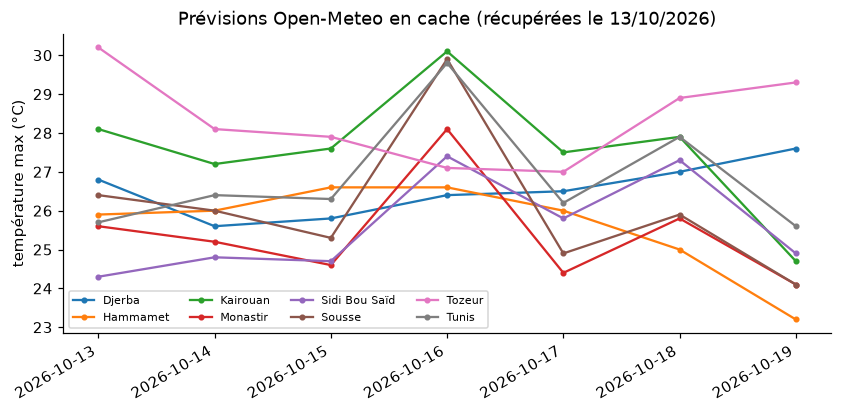

 ville       date  temp_min  temp_max  precipitations  code_meteo
Djerba 2026-10-13      23.2      26.8             0.4          80
Djerba 2026-10-14      20.7      25.6             0.0           2
Djerba 2026-10-15      20.8      25.8             0.0           2
Djerba 2026-10-16      18.8      26.4             0.0           3
Djerba 2026-10-17      20.8      26.5             0.6           3
Djerba 2026-10-18      21.3      27.0             0.0           3
Djerba 2026-10-19      24.5      27.6             0.0           3


In [17]:
meteo["date"] = pd.to_datetime(meteo["date"])
fig, ax = plt.subplots(figsize=(9, 4))
for ville, g in meteo.sort_values("date").groupby("ville"):
    ax.plot(g.date, g.temp_max, marker="o", ms=3, label=ville)
ax.set_ylabel("température max (°C)")
ax.set_title(f"Prévisions Open-Meteo en cache (récupérées le {meteo.maj_le.max():%d/%m/%Y})")
ax.legend(fontsize=7, ncol=4)
fig.autofmt_xdate()
sauver(fig, "etape01_meteo.png")
plt.show()
print(meteo[meteo.ville == "Djerba"].drop(columns="maj_le").to_string(index=False))

## 10. Synthèse chiffrée et biais

In [18]:
part_resto_cafe = pois.type.isin(["restaurant", "cafe"]).mean() * 100
print(f"- {len(pois)} POI sur {pois.ville.nunique()} villes ; {part_resto_cafe:.0f} % sont des restaurants ou cafés.")
print(f"- Ville la plus fournie : {volumes.total.idxmax()} ({volumes.total.max()}) ; "
      f"la moins fournie : {volumes.total.idxmin()} ({volumes.total.min()}).")
print(f"- Arabe manquant : {taux_global['nom_ar']:.0f} % ; anglais manquant : {taux_global['nom_en']:.0f} % ; "
      f"horaires manquants : {taux_global['horaires (brut OSM)']:.0f} % ; prix manquant : {taux_global['prix_moyen']:.0f} %.")
print(f"- Doublons probables (même nom, < 50 m) : {len(doublons)}.")
print(f"- Activités : médiane de distance au POI le plus proche = {activites.poi_plus_proche_km.median():.2f} km ; "
      f"{len(isolees)} activités sans POI à moins de 2 km.")

- 1030 POI sur 8 villes ; 67 % sont des restaurants ou cafés.
- Ville la plus fournie : Tunis (236) ; la moins fournie : Kairouan (35).
- Arabe manquant : 71 % ; anglais manquant : 85 % ; horaires manquants : 93 % ; prix manquant : 100 %.
- Doublons probables (même nom, < 50 m) : 21.
- Activités : médiane de distance au POI le plus proche = 0.20 km ; 13 activités sans POI à moins de 2 km.


**Biais et conséquences pour les étapes suivantes**

- **Biais de cartographie OSM** : les zones touristiques et urbaines (Tunis, Sousse, Hammamet) sont
  mieux cartographiées que le Sud (Tozeur) ; le volume de POI reflète l'activité des contributeurs
  OSM, pas l'intérêt touristique. Le plafond par type limite l'effet, sans l'annuler.
- **Sur-représentation de la restauration** : restaurants et cafés dominent. Le module 3 ne doit pas
  utiliser « nombre de POI autour » comme signal de qualité sans normaliser par type.
- **Prix quasi absents** : OSM ne porte presque jamais de prix. Le budget des repas (module 5) devra
  s'appuyer sur un forfait par type de repas et par ville, documenté comme hypothèse, et non sur `prix_moyen`.
- **Arabe** : la couverture `nom_ar` mesurée ici fixe ce que l'interface arabe pourra afficher ; sinon
  repli sur `nom` (convention i18n du projet), et le LLM peut translittérer à l'affichage.
- **Horaires** : seule une partie est exploitable par le solveur. Pour les autres, l'itinéraire doit
  marquer le créneau comme « horaires à vérifier » plutôt que d'inventer une contrainte.
- **Activités isolées** : les excursions (désert, îles, oasis) partent loin de tout POI ; c'est attendu,
  le solveur doit les traiter comme des demi-journées ou journées autonomes.